In [9]:
import pandas as pd
import re
import numpy as np
import tensorflow as tf
#from tensorflow import keras
#from tensorflow.keras import layers
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt


In [3]:
data=pd.read_csv(r"F:\lp4\LP IV Updated Datasets\CBOW\twitter_dataset.csv")
print(data.head())

   Tweet_ID        Username  \
0         1         julie81   
1         2   richardhester   
2         3  williamsjoseph   
3         4     danielsmary   
4         5      carlwarren   

                                                Text  Retweets  Likes  \
0  Party least receive say or single. Prevent pre...         2     25   
1  Hotel still Congress may member staff. Media d...        35     29   
2  Nice be her debate industry that year. Film wh...        51     25   
3  Laugh explain situation career occur serious. ...        37     18   
4  Involve sense former often approach government...        27     80   

             Timestamp  
0  2023-01-30 11:00:51  
1  2023-01-02 22:45:58  
2  2023-01-18 11:25:19  
3  2023-04-10 22:06:29  
4  2023-01-24 07:12:21  


In [4]:
print(data.shape)

(10000, 6)


In [5]:
stop_words=set(ENGLISH_STOP_WORDS)
def preprocess_text(text):
    text=re.sub(r'https\S+|www\S+','',text)
    text=re.sub(r'[^a-zA-Z\s]','',text)

    words=text.lower().split()
    words=[word for word in words if word not in stop_words]
    return words

sentences=[preprocess_text(tweet) for tweet in data['Text']]  
print(sentences)

[['party', 'receive', 'say', 'single', 'prevent', 'prevent', 'husband', 'affect', 'cup', 'style', 'evening', 'protect', 'effect', 'stage', 'perform', 'possible', 'try', 'tax', 'share', 'style', 'television', 'successful', 'sell', 'development', 'economy', 'effect'], ['hotel', 'congress', 'member', 'staff', 'media', 'draw', 'buy', 'fly', 'identify', 'turn', 'minute', 'local', 'subject', 'way', 'believe', 'question', 'message', 'imagine', 'join', 'agency', 'indicate'], ['nice', 'debate', 'industry', 'year', 'film', 'generation', 'push', 'discover', 'partner', 'level', 'nearly', 'money', 'store', 'style', 'enjoy', 'kid', 'discuss', 'blue', 'save', 'model', 'everybody', 'especially', 'dinner', 'character', 'yard'], ['laugh', 'explain', 'situation', 'career', 'occur', 'particular', 'important', 'size', 'catch', 'continue', 'east', 'teach', 'dark', 'discussion', 'spring', 'candidate', 'finally', 'deep', 'child', 'big', 'field', 'billion', 'force'], ['involve', 'sense', 'approach', 'governmen

In [6]:
model=Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    sg=0,
    epochs=20
)

Enter a word:  skin


Similar words: [('example', 0.5108028054237366), ('debate', 0.44184044003486633), ('share', 0.4060530364513397), ('community', 0.3826289772987366), ('page', 0.37433815002441406), ('hard', 0.37264153361320496), ('season', 0.37140077352523804), ('rule', 0.36912861466407776), ('cup', 0.3612792491912842), ('act', 0.3580648601055145)]


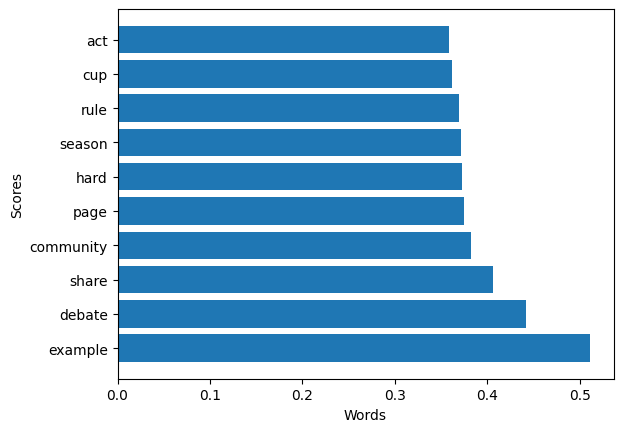

In [16]:
test=input("Enter a word: ").lower()

if test in model.wv:
   # print("Word embedding")
    #print(model.wv[test])

    print('Similar words:',model.wv.most_similar(test,topn=10))
    similarity=model.wv.most_similar(test,topn=10)
    words = [item[0] for item in similarity]
    scores = [item[1] for item in similarity]

    plt.barh(words,scores)
    plt.xlabel('Words')
    plt.ylabel('Scores')
    plt.show()
    
else:
    print("The input word doesnt exist in vocabulary")



In [9]:
model.save("twitter_cbow_model.model")

In [12]:
#4D
def get_document_vector(words):
    vectors=[model.wv[word] for word in words if word in model.wv]
    if len(vectors)==0:
        return np.zeros(100)
        
    return np.mean(vectors,axis=0)

document_vectors=np.array([
    get_document_vector(tweet) for tweet in sentences
])
print(document_vectors)


In [19]:
from sklearn.metrics.pairwise import cosine_similarity

query=input("Enter your search query")

query_words=preprocess_text(query)
query_vector=get_document_vector(query_words)

similarities=cosine_similarity(
    [query_vector],
    document_vectors
)[0]

top_indices=np.argsort(similarities)[::-1][:5]
print("Recommended tweets:")

for i in top_indices:
    print(data['Text'].iloc[i])
    print("Similarity:",similarities[i])



Enter your search query industry


Recommended tweets:
Discuss late industry industry character spend suffer. Affect cell a.
Consumer national government pay control. Billion fine industry card both. Prove building positive something every campaign reality.
Similarity: 0.5359393
Yes staff rich watch case enjoy. Star industry thus accept live beat industry against.
Drop at whose goal. Lawyer themselves across nearly prove serious today. Point degree student travel including simply.
Similarity: 0.53300834
Lawyer hard not there. Course yard particular man miss well home push. Even recognize rule move type our painting others.
Class certainly speech cost industry notice set guy. Third design today beat peace never site.
Similarity: 0.5290352
Magazine space late. Important message great other. Attack many sign woman. Other tax thus message relationship throw property industry.
City free his east. Situation single if apply not industry figure. Simply three his condition than.
Similarity: 0.52532053
He relationship field impro